# Nutrition5k: vistas cenital y lateral, y qué recorte usar

No entrena nada. Nutrition5k tiene dos tipos de imagen por plato:

- **Laterales** (`imagery/side_angles/`): cuatro cámaras que giran alrededor del plato y graban vídeo a 1920×1080
  (Thames et al., p.4). Es lo que usa este proyecto (un frame de cada 5, guardado con el lado corto a 320 px).
- **Cenitales** (`imagery/realsense_overhead/`): una única captura desde arriba con una Intel RealSense D435:
  `rgb.png`, `depth_raw.png` (profundidad de 16 bits; ×1e-4 = metros) y `depth_color.png` (solo para visualizar).

Responde a:

1. Cuántos platos hay de cada tipo y cómo se solapan los splits oficiales.
2. Qué problema tiene el recorte actual en las laterales.
3. Cómo es una imagen cenital y su profundidad.
4. Dónde cae el plato en las cenitales y qué recorte cuadrado fijo lo conserva mejor.

Las cenitales no las descarga `prepare`: la celda de configuración baja una muestra de platos de `depth_train`
(solo train, para que test no influya en la elección del recorte) a `data/nutrition5k/imagery/realsense_overhead/`.
Decisión y contexto: `notes/decisions_and_concepts/overhead-view-and-crop.md`.

In [1]:
import os
import random
import urllib.request
from pathlib import Path

if Path("/workspace").is_dir():  # RunPod
    os.chdir("/root/thesis-multimodal-health-ai")
elif Path.cwd().parent.parent.name == "notebooks":
    os.chdir("../../..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle
from PIL import Image

from nutrition5k.dataset import FRAME_DIRS, PILOT_SEED
from nutrition5k.fetch import GCS_BASE_URL

ROOT = Path("data/nutrition5k")
OVERHEAD = ROOT / "imagery/realsense_overhead"
SAMPLE_SIZE = 60          # platos cenitales de depth_train para medir dónde cae el plato
NEAR, FAR = 0.20, 0.37    # m; plato y comida están más cerca de la cámara que el fondo del montaje
INPUT = 224               # resolución de entrada actual
SERIES = ("#2a78d6", "#eb6834", "#1baf7a", "#eda100")
INK, MUTED = "#0b0b0b", "#52514e"


def fetch(relative, destination):
    """Download one file of the public bucket unless it is already there."""
    if not destination.is_file():
        destination.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f"{GCS_BASE_URL}/{relative}", destination)
    return destination


def read_ids(relative):
    return fetch(relative, ROOT / relative).read_text().split()


splits = {name: read_ids(f"dish_ids/splits/{name}_ids.txt") for name in ("rgb_train", "rgb_test", "depth_train", "depth_test")}
sample = random.Random(PILOT_SEED).sample(splits["depth_train"], SAMPLE_SIZE)
for dish in sample:
    for name in ("rgb.png", "depth_raw.png"):
        fetch(f"imagery/realsense_overhead/{dish}/{name}", OVERHEAD / dish / name)
print(f"{len(sample)} platos cenitales en {OVERHEAD}")

60 platos cenitales en data/nutrition5k/imagery/realsense_overhead


## 1. Cuántas imágenes hay de cada tipo

Los splits oficiales: `rgb_*` para las laterales y `depth_*` para las cenitales. `con frames` cuenta los platos con
frames laterales extraídos en `data/` (modo `complete`).

In [2]:
side_dir = ROOT / "imagery/side_angles"
with_frames = {d.name for d in side_dir.iterdir() if any((d / FRAME_DIRS["complete"]).glob("*.jpeg"))} if side_dir.is_dir() else set()
rows = []
for view, prefix in (("lateral", "rgb"), ("cenital", "depth")):
    for part in ("train", "test"):
        ids = set(splits[f"{prefix}_{part}"])
        rows.append({"vista": view, "split": part, "platos": len(ids),
                     "también en el split del otro tipo": len(ids & set(splits[f"{'depth' if prefix == 'rgb' else 'rgb'}_{part}"])),
                     "con frames laterales": len(ids & with_frames)})
display(pd.DataFrame(rows).set_index(["vista", "split"]))

platos  también en el split del otro tipo  con frames laterales
vista   split                                                                 
lateral train    4059                               2758                  3930
        test      709                                507                   676
cenital train    2758                               2758                  2641
        test      507                                507                   474

Por plato, la vista lateral da muchas imágenes (4 cámaras × varios frames) y la cenital **una sola** foto, pero
con profundidad real.

## 2. Vistas laterales: el problema del recorte

Recorte cuadrado con la altura máxima (lado = alto del frame) centrado en horizontal. Los frames son 16:9, así que
aun usando todo el alto el recorte se queda con 9/16 ≈ **56 % del ancho**: lo que hay a los lados del plato no llega al
modelo, aunque el modelo tiene que predecir el plato entero. Thames et al. (§4.2, p.5) y Bianco et al. (§2.2.3, p.5) también
recortan el centro. Además, las cámaras miran desde unos 30° y 60° sobre la horizontal y giran, así que cada frame
ve el plato desde otro ángulo y con oclusiones distintas.

In [ ]:
def centre_crop_box(width, height):
    """Largest centred square: side = shorter side (the full height in landscape frames)."""
    side = min(width, height)
    return (width - side) / 2, (height - side) / 2, side


def show_crop(ax, image, boxes, title):
    ax.imshow(image)
    for (x0, y0, side), color in boxes:
        ax.add_patch(Rectangle((x0, y0), side, side, fill=False, edgecolor=color, linewidth=2))
    ax.set_title(title, loc="left", color=INK, fontsize=10)
    ax.axis("off")


EXAMPLE = "dish_1563827132"  # tiene vista lateral y cenital
frames = sorted((side_dir / EXAMPLE / FRAME_DIRS["complete"]).glob("*.jpeg"))
picked = [next(f for f in frames if f.name.startswith(f"camera_{c}")) for c in "ABCD"]
fig, axes = plt.subplots(1, 4, figsize=(16, 2.6))
for ax, path in zip(axes, picked):
    image = Image.open(path).convert("RGB")
    show_crop(ax, image, [(centre_crop_box(*image.size), SERIES[1])], f"{path.stem} {image.size[0]}×{image.size[1]}")
plt.suptitle("Laterales: en naranja el recorte cuadrado de altura máxima centrado", x=0.01, ha="left", color=MUTED)
plt.tight_layout()
plt.show()

x0, y0, side = centre_crop_box(*Image.open(picked[0]).size)
print(f"El recorte central conserva {side / Image.open(picked[0]).size[0]:.0%} del ancho y {side / Image.open(picked[0]).size[1]:.0%} del alto")

## 3. Vista cenital: RGB y profundidad

La profundidad mide la distancia a la cámara: el plato y la comida están más cerca que el fondo del montaje (unos
36 cm; Thames et al. dan 35.9 cm de cámara a plano). Los píxeles a 0 son agujeros sin medida. La profundidad no está
perfectamente alineada píxel a píxel con la RGB.

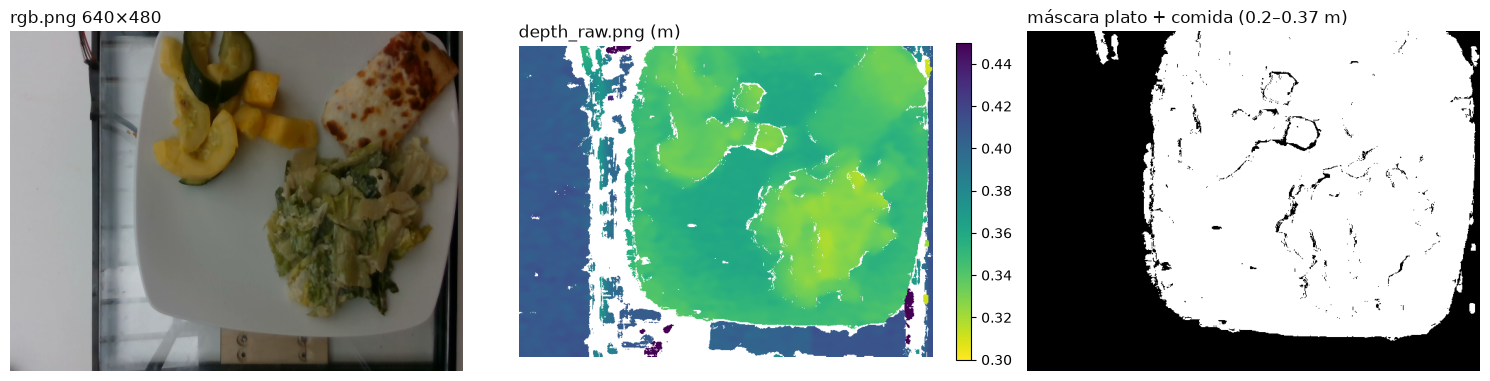

sin medida: 14.0% de los píxeles; mediana de la profundidad medida: 0.352 m


In [4]:
def load_overhead(dish):
    rgb = Image.open(fetch(f"imagery/realsense_overhead/{dish}/rgb.png", OVERHEAD / dish / "rgb.png")).convert("RGB")
    depth = np.asarray(Image.open(fetch(f"imagery/realsense_overhead/{dish}/depth_raw.png", OVERHEAD / dish / "depth_raw.png"))) * 1e-4
    return rgb, depth


rgb, depth = load_overhead(EXAMPLE)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].imshow(rgb); axes[0].set_title(f"rgb.png {rgb.size[0]}×{rgb.size[1]}", loc="left", color=INK)
shown = axes[1].imshow(np.where(depth > 0, depth, np.nan), cmap="viridis_r", vmin=0.30, vmax=0.45)
axes[1].set_title("depth_raw.png (m)", loc="left", color=INK)
fig.colorbar(shown, ax=axes[1], fraction=0.035)
axes[2].imshow((depth > NEAR) & (depth < FAR), cmap="gray")
axes[2].set_title(f"máscara plato + comida ({NEAR}–{FAR} m)", loc="left", color=INK)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()
print(f"sin medida: {(depth == 0).mean():.1%} de los píxeles; mediana de la profundidad medida: {np.median(depth[depth > 0]):.3f} m")

## 4. Dónde cae el plato y qué recorte usar

Para cada plato de la muestra, la máscara de profundidad (`NEAR`–`FAR`) marca el plato y la comida. La caja del plato
son las columnas y filas con al menos un 25 % de píxeles en la máscara.

In [5]:
masks = {dish: (lambda d: (d > NEAR) & (d < FAR))(load_overhead(dish)[1]) for dish in sample}


def plate_box(mask):
    cols, rows = np.where(mask.mean(0) > 0.25)[0], np.where(mask.mean(1) > 0.25)[0]
    return cols.min(), cols.max(), rows.min(), rows.max()


boxes = pd.DataFrame([plate_box(m) for m in masks.values()], index=list(masks), columns=["x0", "x1", "y0", "y1"])
boxes["ancho"], boxes["alto"] = boxes["x1"] - boxes["x0"], boxes["y1"] - boxes["y0"]
display(boxes.describe(percentiles=[0.05, 0.5, 0.95]).loc[["min", "5%", "50%", "95%", "max"]].round(0))
CX = int(round((boxes["x0"].median() + boxes["x1"].median()) / 2))
CY = int(round((boxes["y0"].median() + boxes["y1"].median()) / 2))
print(f"Centro mediano del plato: ({CX}, {CY}); centro de la imagen: (320, 240)")

,x0,x1,y0,y1,ancho,alto
min,97.0,491.0,0.0,323.0,231.0,207.0
5%,116.0,519.0,0.0,371.0,337.0,318.0
50%,148.0,592.0,0.0,446.0,454.0,441.0
95%,236.0,632.0,90.0,479.0,488.0,479.0
max,280.0,639.0,134.0,479.0,505.0,479.0


Centro mediano del plato: (370, 223); centro de la imagen: (320, 240)


**Cobertura** de un recorte = fracción de los píxeles de la máscara (plato + comida) que quedan dentro. Candidatos:

- `centre 420`: lo que hace hoy la transformación de timm en una imagen 640×480 (lado corto 480 → 256, recorte 224,
  equivale a un cuadrado de 420 px centrado en la imagen).
- `fixed N`: cuadrado de N px centrado en el centro mediano del plato (desplazado para no salirse de la imagen).

In [6]:
def square(side, cx, cy, width=640, height=480):
    x0 = min(max(cx - side // 2, 0), width - side)
    y0 = min(max(cy - side // 2, 0), height - side)
    return x0, y0, side


def coverage(mask, box):
    x0, y0, side = box
    return mask[y0:y0 + side, x0:x0 + side].sum() / mask.sum()


CANDIDATES = {"centre 420": square(420, 320, 240), **{f"fixed {s}": square(s, CX, CY) for s in (420, 448, 480)}}
table = pd.DataFrame({name: [coverage(m, box) for m in masks.values()] for name, box in CANDIDATES.items()}, index=list(masks))
summary = table.describe(percentiles=[0.05]).loc[["mean", "5%", "min"]].T
summary["caja (x0, y0, lado)"] = [CANDIDATES[name] for name in summary.index]
display((summary.style.format({"mean": "{:.1%}", "5%": "{:.1%}", "min": "{:.1%}"})))

,mean,5%,min,"caja (x0, y0, lado)"
centre 420,84.0%,74.7%,71.2%,"(110, 30, 420)"
fixed 420,90.4%,82.5%,79.9%,"(160, 13, 420)"
fixed 448,95.6%,89.7%,88.0%,"(146, 0, 448)"
fixed 480,98.5%,95.9%,93.5%,"(130, 0, 480)"


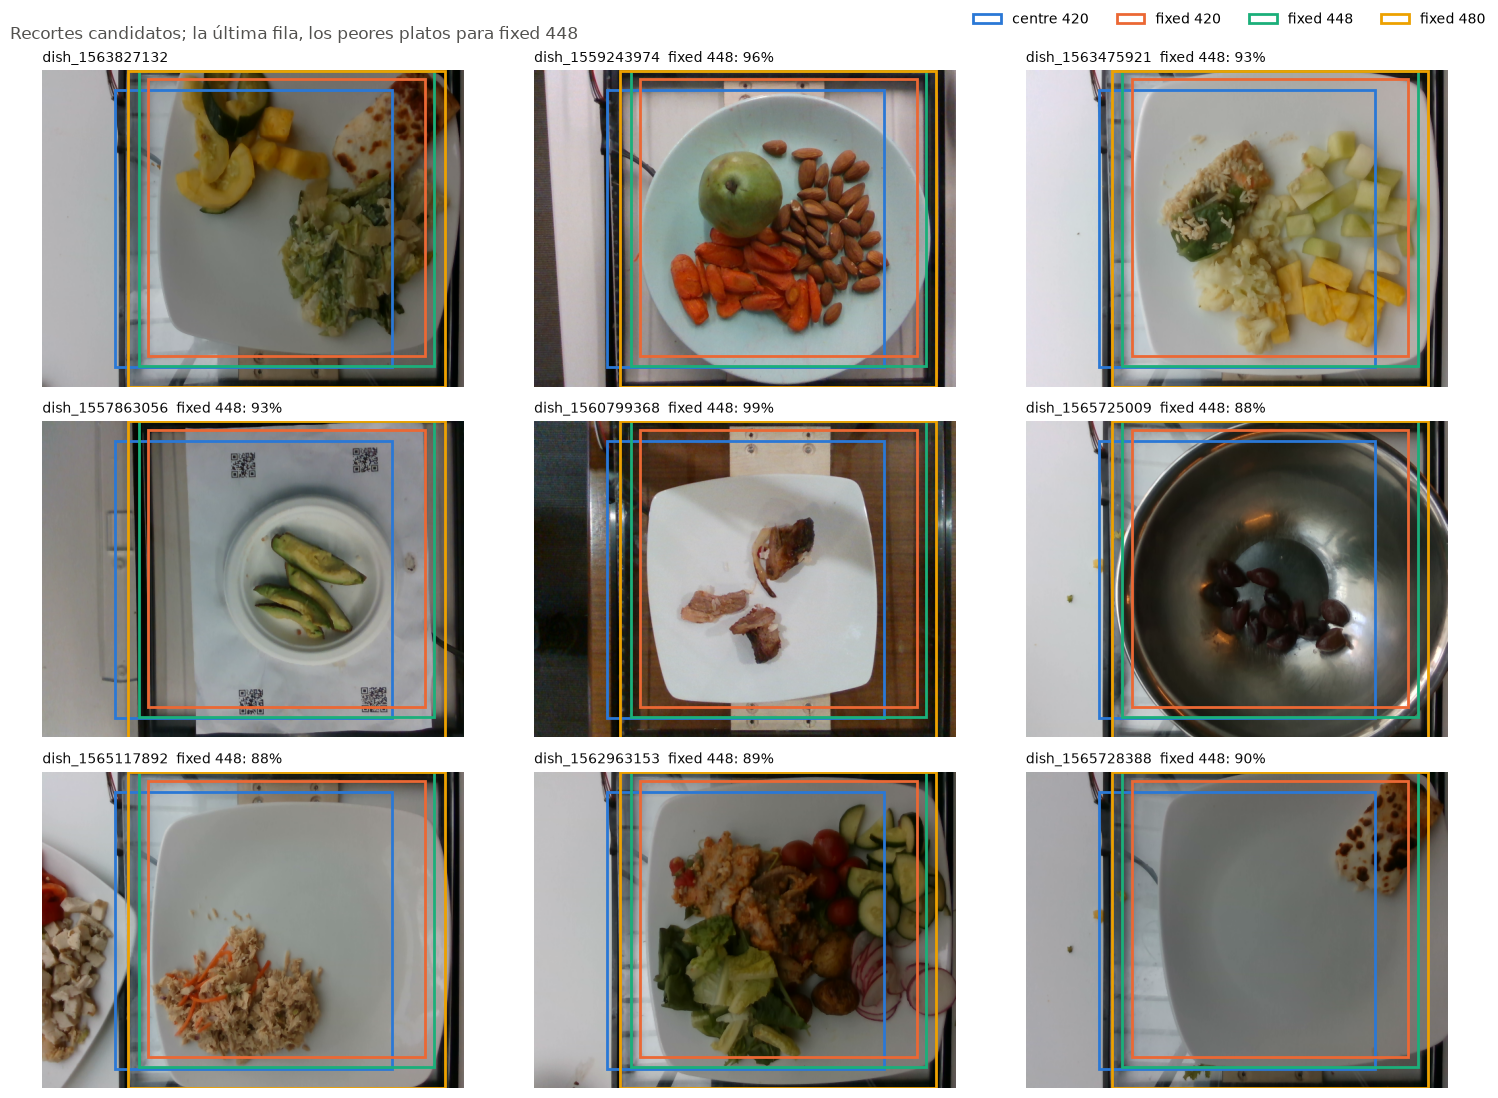

In [7]:
worst = table["fixed 448"].nsmallest(4).index
show = [EXAMPLE, *[d for d in sample[:8] if d not in worst][:4], *worst]
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, dish in zip(axes.flat, show):
    image, _ = load_overhead(dish)
    show_crop(ax, image, [(CANDIDATES[name], color) for name, color in zip(CANDIDATES, SERIES)],
              f"{dish}  fixed 448: {coverage(masks[dish], CANDIDATES['fixed 448']):.0%}" if dish in masks else dish)
fig.legend(handles=[Rectangle((0, 0), 1, 1, fill=False, edgecolor=c, linewidth=2) for c in SERIES], labels=list(CANDIDATES),
           loc="upper right", ncols=4, frameon=False)
plt.suptitle("Recortes candidatos; la última fila, los peores platos para fixed 448", x=0.01, ha="left", color=MUTED)
plt.tight_layout()
plt.show()

### Cómo queda lo que ve el modelo

**Recorte escogido: `fixed 448`, redimensionado a 224**, que es justo la mitad (cada píxel de entrada resume un
bloque exacto de 2×2 píxeles). Se muestra también 448 → 384 como referencia: encaja con ViT de patch 16 (24×24
tokens) y con las MobileNet (/32), pero cuesta unas 2.9 veces los MACs de 224.

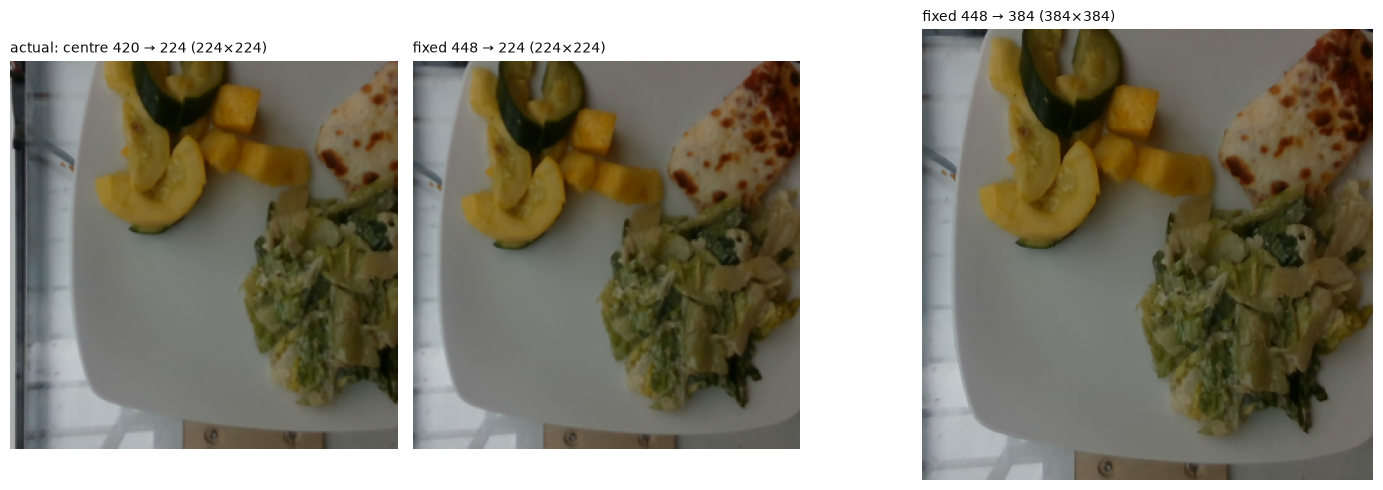

In [8]:
x0, y0, side = CANDIDATES["fixed 448"]
cx0, cy0, cside = CANDIDATES["centre 420"]
views = {
    f"actual: centre 420 → {INPUT}": rgb.crop((cx0, cy0, cx0 + cside, cy0 + cside)).resize((INPUT, INPUT), Image.BICUBIC),
    f"fixed 448 → {INPUT}": rgb.crop((x0, y0, x0 + side, y0 + side)).resize((INPUT, INPUT), Image.BICUBIC),
    "fixed 448 → 384": rgb.crop((x0, y0, x0 + side, y0 + side)).resize((384, 384), Image.BICUBIC),
}
fig, axes = plt.subplots(1, 3, figsize=(15, 5), gridspec_kw={"width_ratios": [224, 224, 384]})
for ax, (title, image) in zip(axes, views.items()):
    ax.imshow(image)
    ax.set_title(f"{title} ({image.size[0]}×{image.size[1]})", loc="left", color=INK, fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

## Conclusiones

- Las laterales ven medio frame con el recorte actual; las cenitales pierden menos con el mismo recorte (4:3 en vez
  de 16:9), pero el plato está desplazado a la derecha y el recorte central corta ese lado.
- Un recorte fijo cuadrado centrado en el plato conserva casi todo el plato. **Se escoge `fixed 448`** (cabe en
  los 480 px de alto) **y se redimensiona a 224, que es justo la mitad**.
- La cobertura se mide con una máscara de profundidad aproximada (umbral fijo, profundidad no alineada del todo con
  la RGB) sobre una muestra de train; es una guía para elegir el recorte, no un resultado del modelo.
- Todavía no está en el entrenamiento: decisión en `notes/decisions_and_concepts/overhead-view-and-crop.md`.